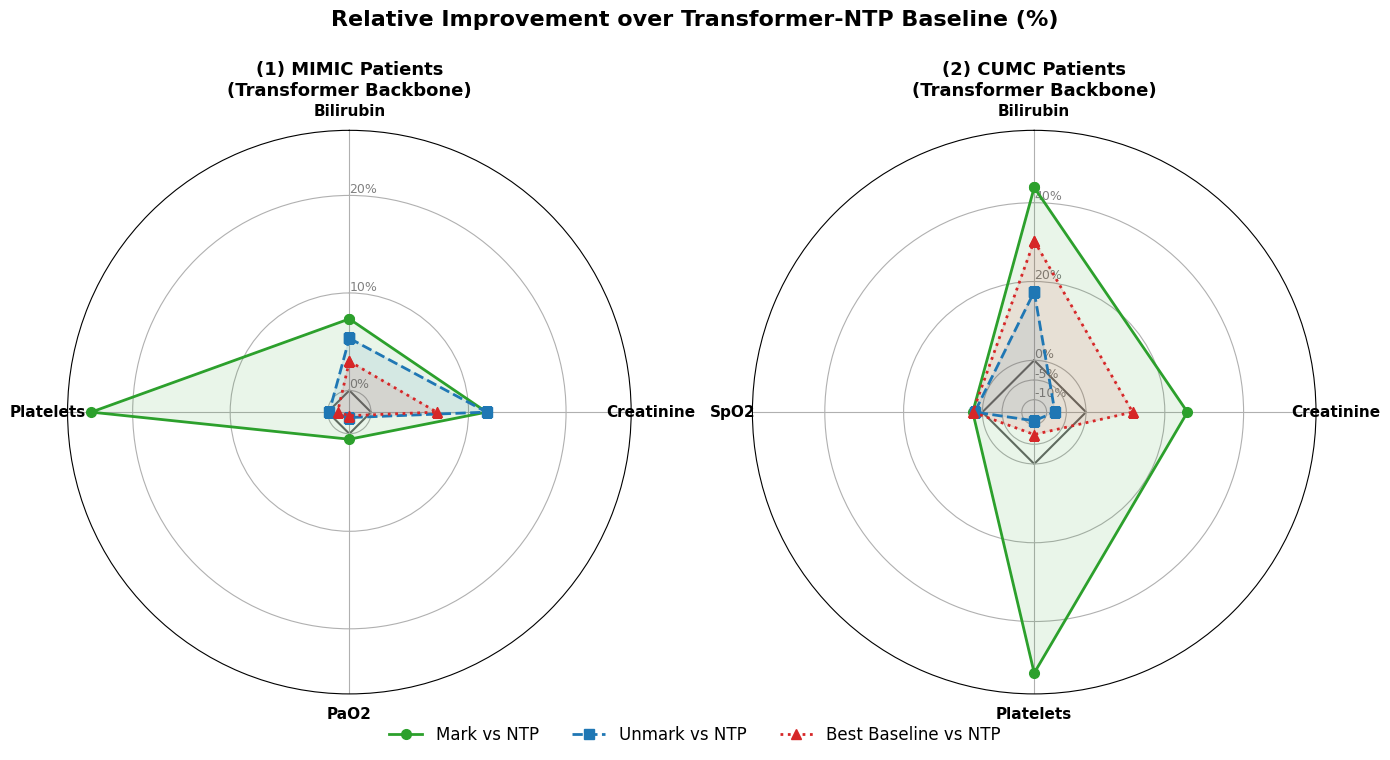

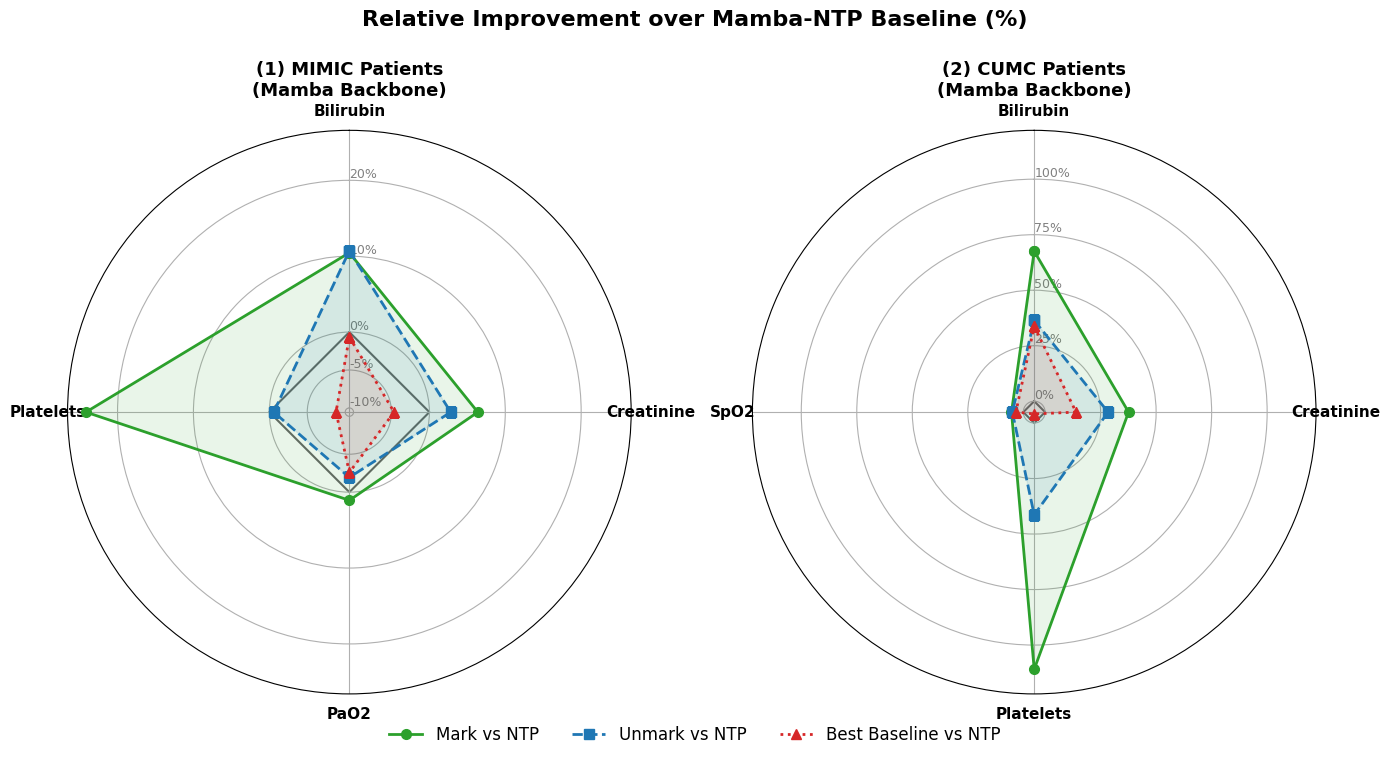

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# Data Preparation (Calculated from Tables)
# ==========================================

# Data structure:
# {
#   'Title': 'MIMIC - Transformer Backbone',
#   'Tasks': ['Bili', 'Crea', 'PaO2', 'Plat'],
#   'Data': {
#       'Mark vs NTP': [val1, val2, val3, val4],
#       'Unmark vs NTP': [...],
#       'Best Baseline (Motor) vs NTP': [...]
#   }
# }

# --- GRAPH 1 DATA: TRANSFORMER BACKBONE ---

# MIMIC RMSE (Lower is better. Imprv = (NTP - Model) / NTP)
# Anchor: Transformer-ntp [5.423, 1.038, 55.888, 107.198]
# Best Baseline: Motor [5.261, 0.968, 56.920, 108.285]
data_mimic_trans = {
    'Title': '(1) MIMIC Patients\n(Transformer Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'PaO2', 'Platelets'],
    'Data': {
        # Calculated from table or re-verified
        'Mark vs NTP': [7.34, 11.85, 0.56, 24.25],
        # Calc: (5.423-5.133)/5.423, (1.038-0.915)/1.038, etc.
        'Unmark vs NTP': [5.35, 11.85, -1.66, -0.15],
        # Calc: (5.423-5.261)/5.423, (1.038-0.968)/1.038, etc.
        'Best Baseline vs NTP': [2.99, 6.74, -1.85, -1.01]
    }
}

# CUMC R2 (Higher is better. Imprv = (Model - NTP) / NTP)
# Anchor: Transformer-ntp [0.155, 0.431, 0.228, 0.816]
# Best Baseline: Motor [0.202, 0.482, 0.211, 0.836]
data_cumc_trans = {
    'Title': '(2) CUMC Patients\n(Transformer Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'Platelets', 'SpO2'],
    'Data': {
        # Calculated from table
        'Mark vs NTP': [43.87, 25.75, 53.07, 2.45],
        # Calc: (0.182-0.155)/0.155, etc.
        'Unmark vs NTP': [17.42, -7.89, -10.96, 1.96],
        # Calc: (0.202-0.155)/0.155, etc.
        'Best Baseline vs NTP': [30.32, 11.83, -7.46, 2.45]
    }
}


# --- GRAPH 2 DATA: MAMBA BACKBONE ---

# MIMIC RMSE (Lower is better)
# Anchor: Mamba-ntp [5.227, 0.925, 55.475, 99.533]
# Best Baseline: Motor [5.261, 0.968, 56.920, 108.285]
data_mimic_mamba = {
    'Title': '(1) MIMIC Patients\n(Mamba Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'PaO2', 'Platelets'],
    'Data': {
        # Calculated from table (small deviations due to table rounding)
        'Mark vs NTP': [10.46, 6.38, 1.08, 24.17],
        'Unmark vs NTP': [10.71, 2.81, -1.94, -0.58],
        'Best Baseline vs NTP': [-0.65, -4.65, -2.60, -8.79]
    }
}

# CUMC R2 (Higher is better)
# Anchor: Mamba-ntp [0.151, 0.423, 0.220, 0.809]
# Best Baseline: Motor [0.202, 0.482, 0.211, 0.836]
data_cumc_mamba = {
    'Title': '(2) CUMC Patients\n(Mamba Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'Platelets', 'SpO2'],
    'Data': {
        # Calculated from table
        'Mark vs NTP': [67.55, 37.59, 110.91, 5.32],
        'Unmark vs NTP': [36.42, 28.37, 41.36, 4.94],
        'Best Baseline vs NTP': [33.77, 13.95, -4.09, 3.34]
    }
}

# ==========================================
# Plotting Helper Function
# ==========================================
def make_radar_chart(ax, data_dict, colors, line_styles, markers):
    """
    Generates a single radar chart on the provided axes.
    Handles negative values by adjusting the center floor.
    """
    tasks = data_dict['Tasks']
    datasets = data_dict['Data']
    
    # Number of variables
    N = len(tasks)
    
    # What will be the angle of each axis in the plot?
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1] # Close the loop
    
    # Find global min/max for scaling axes intelligently
    all_values = [val for sublist in datasets.values() for val in sublist]
    max_val = max(all_values)
    min_val = min(all_values)
    
    # Determine radial limits. 
    # Crucial: Set the floor below zero if negative values exist so they are visible.
    # We want 0% improvement to be a clear, distinct ring.
    
    # Define the "floor" of the chart. If min_val is -10, floor might be -15.
    # If all are positive, floor is 0.
    floor = min(0, min_val * 1.2) if min_val < 0 else 0
    
    # Define ceiling with some padding
    ceiling = max_val * 1.1
    
    # Set visual properties for the radar background
    ax.set_theta_offset(np.pi / 2) # Rotate so first task is at top
    ax.set_theta_direction(-1) # Clockwise
    
    # Draw one axe per variable + add labels
    plt.xticks(angles[:-1], tasks, color='black', size=11, weight='bold')
    
    # Draw ylabels
    ax.set_rlabel_position(0)
    
    # Define grid settings based on data range
    if ceiling > 100:
        grids = [0, 25, 50, 75, 100]
    elif ceiling > 50:
         grids = [0, 20, 40, 60]
    else:
         grids = [0, 10, 20, 30]

    # Add negative grids if necessary
    if floor < 0:
        # Add grids below zero, e.g., -10, -5
        neg_grids = np.arange(np.floor(floor/5)*5, 0, 5).tolist()
        grids = neg_grids + grids
        
    # Filter grids that are outside the view range
    grids = [g for g in grids if g >= floor and g <= ceiling]
    
    plt.yticks(grids, [str(int(g))+"%" for g in grids], color="grey", size=9)
    plt.ylim(floor, ceiling)

    # Highlight the 0% line (the NTP anchor equivalent)
    ax.plot(angles, [0]*len(angles), linestyle='-', linewidth=1.5, color='black', alpha=0.6, zorder=1)

    # Plot each model
    for i, (model_name, values) in enumerate(datasets.items()):
        values_closed = values + values[:1] # Close the loop
        ax.plot(angles, values_closed, 
                color=colors[i], 
                linewidth=2, 
                linestyle=line_styles[i], 
                marker=markers[i], markersize=7, 
                label=model_name, zorder=3)
        ax.fill(angles, values_closed, color=colors[i], alpha=0.1, zorder=2)
        
    ax.set_title(data_dict['Title'], size=13, weight='bold', pad=25)

# ==========================================
# Main Plotting Execution
# ==========================================

# Define aesthetics for the three comparison lines
colors = ['#2ca02c', '#1f77b4', '#d62728'] # Green (Mark), Blue (Unmark), Red (Best Base)
line_styles = ['-', '--', ':']
markers = ['o', 's', '^']

# --- Figure 1: Transformer Backbone ---
fig1 = plt.figure(figsize=(14, 7))
fig1.suptitle("Relative Improvement over Transformer-NTP Baseline (%)", size=16, weight='bold', y=1.02)

# Subgraph 1: MIMIC Transformer
ax1 = fig1.add_subplot(121, polar=True)
make_radar_chart(ax1, data_mimic_trans, colors, line_styles, markers)

# Subgraph 2: CUMC Transformer
ax2 = fig1.add_subplot(122, polar=True)
make_radar_chart(ax2, data_cumc_trans, colors, line_styles, markers)

# Add a common legend
handles, labels = ax1.get_legend_handles_labels()
fig1.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), 
            ncol=3, frameon=False, fontsize=12)

plt.tight_layout()
fig1.savefig('transformer_improvement_radar.png', bbox_inches='tight', dpi=300)
plt.show()


# --- Figure 2: Mamba Backbone ---
fig2 = plt.figure(figsize=(14, 7))
fig2.suptitle("Relative Improvement over Mamba-NTP Baseline (%)", size=16, weight='bold', y=1.02)

# Subgraph 1: MIMIC Mamba
ax3 = fig2.add_subplot(121, polar=True)
make_radar_chart(ax3, data_mimic_mamba, colors, line_styles, markers)

# Subgraph 2: CUMC Mamba
ax4 = fig2.add_subplot(122, polar=True)
make_radar_chart(ax4, data_cumc_mamba, colors, line_styles, markers)

# Add a common legend
handles, labels = ax3.get_legend_handles_labels()
fig2.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), 
            ncol=3, frameon=False, fontsize=12)

plt.tight_layout()
fig2.savefig('mamba_improvement_radar.png', bbox_inches='tight', dpi=300)
plt.show()

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Set publication-quality defaults
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

# ==========================================
# Data Preparation
# ==========================================

# --- TRANSFORMER BACKBONE DATA ---
data_mimic_trans = {
    'Title': 'MIMIC',
    'Tasks': ['Bilirubin', 'Creatinine', 'PaO₂', 'Platelets'],
    'Data': {
        'Best Baseline vs NTP': [2.99, 6.74, -1.85, -1.01],
        'Unmark vs NTP': [5.35, 11.85, -1.66, -0.15],
        'Mark vs NTP': [7.34, 11.85, 0.56, 24.25],
    }
}

data_cumc_trans = {
    'Title': 'CUMC',
    'Tasks': ['Bilirubin', 'Creatinine', 'SpO₂','Platelets'],
    'Data': {
        'Best Baseline vs NTP': [30.32, 11.83, 2.45,-7.46],
        'Unmark vs NTP': [17.42, -7.89, 1.96,-10.96],
        'Mark vs NTP': [43.87, 25.75, 2.45,53.07],
    }
}

# --- MAMBA BACKBONE DATA ---
data_mimic_mamba = {
    'Title': 'MIMIC',
    'Tasks': ['Bilirubin', 'Creatinine', 'PaO₂', 'Platelets'],
    'Data': {
        'Best Baseline vs NTP': [-0.65, -4.65, -2.60, -8.79],
        'Unmark vs NTP': [10.71, 2.81, -1.94, -0.58],
        'Mark vs NTP': [10.46, 6.38, 1.08, 24.17],
    }
}

data_cumc_mamba = {
    'Title': 'CUMC',
    'Tasks': ['Bilirubin', 'Creatinine', 'SpO₂','Platelets'],
    'Data': {
        'Best Baseline vs NTP': [33.77, 13.95, 3.34,-4.09],
        'Unmark vs NTP': [36.42, 28.37, 4.94,41.36],
        'Mark vs NTP': [67.55, 37.59, 5.32,110.91],
    }
}

# ==========================================
# Professional color scheme
# ==========================================
COLORS = {
    'Best Baseline vs NTP': '#D62728',  # Red
    'Unmark vs NTP': '#1F77B4',          # Blue  
    'Mark vs NTP': '#2CA02C',            # Green
}
MARKERS = {
    'Best Baseline vs NTP': '^',
    'Unmark vs NTP': 's',
    'Mark vs NTP': 'o',
}
LINESTYLES = {
    'Best Baseline vs NTP': ':',
    'Unmark vs NTP': '--',
    'Mark vs NTP': '-',
}

# ==========================================
# Improved Radar Chart Function
# ==========================================
def make_radar_chart(ax, data_dict, show_annotations=True):
    """
    Creates a clean, publication-ready radar chart.
    """
    tasks = data_dict['Tasks']
    datasets = data_dict['Data']
    N = len(tasks)
    
    # Compute angles - rotate so top is at 45 degrees to avoid overlap
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]
    
    # Find data range for scaling
    all_values = [val for sublist in datasets.values() for val in sublist]
    max_val = max(all_values)
    min_val = min(all_values)
    
    # Set floor and ceiling with padding
    floor = min(-5, min_val - abs(min_val) * 0.2) if min_val < 0 else -5
    ceiling = max_val * 1.25
    
    # Configure polar plot
    ax.set_theta_offset(np.pi / 2)  # Start from top
    ax.set_theta_direction(-1)       # Clockwise
    
    # Remove default tick labels
    ax.set_xticklabels([])
    
    # Add task labels with careful positioning
    for i, (angle, task) in enumerate(zip(angles[:-1], tasks)):
        angle_deg = np.degrees(angle) % 360
        
        # Calculate label position outside the chart
        label_r = ceiling * 1.18
        
        # Adjust alignment based on angle
        if 350 < angle_deg or angle_deg < 10:  # Top
            ha, va = 'center', 'bottom'
        elif 80 < angle_deg < 100:  # Right
            ha, va = 'left', 'center'
        elif 170 < angle_deg < 190:  # Bottom
            ha, va = 'center', 'top'
        elif 260 < angle_deg < 280:  # Left
            ha, va = 'right', 'center'
        elif angle_deg <= 80:  # Top-right quadrant
            ha, va = 'left', 'bottom'
        elif angle_deg <= 170:  # Bottom-right quadrant
            ha, va = 'left', 'top'
        elif angle_deg <= 260:  # Bottom-left quadrant
            ha, va = 'right', 'top'
        else:  # Top-left quadrant
            ha, va = 'right', 'bottom'
        
        ax.text(angle, label_r, task,
                ha=ha, va=va,
                fontsize=12, fontweight='bold',
                color='#2C3E50')
    
    # Set up radial grid
    if ceiling > 100:
        step = 25
    elif ceiling > 50:
        step = 20
    else:
        step = 10
    
    # Create grid values
    grid_values = list(range(0, int(ceiling) + step, step))
    if floor < 0:
        neg_grids = list(range(int(np.floor(floor / 10) * 10), 0, 10))
        grid_values = neg_grids + grid_values
    
    grid_values = [g for g in grid_values if floor <= g <= ceiling]
    
    # Style the radial axis
    ax.set_ylim(floor, ceiling)
    ax.set_yticks(grid_values)
    ax.set_yticklabels([f'{int(g)}%' for g in grid_values], 
                       fontsize=9, color='#666666')
    
    # Style the grid
    ax.yaxis.grid(True, linestyle='-', alpha=0.25, color='#999999', linewidth=0.8)
    ax.xaxis.grid(True, linestyle='-', alpha=0.25, color='#999999', linewidth=0.8)
    
    # Highlight the 0% reference line
    zero_line = [0] * (N + 1)
    ax.plot(angles, zero_line, linestyle='-', linewidth=2.5, 
            color='#333333', alpha=0.7, zorder=5)
    
    # Plot each model's data
    for model_name, values in datasets.items():
        values_closed = values + values[:1]
        color = COLORS[model_name]
        marker = MARKERS[model_name]
        linestyle = LINESTYLES[model_name]
        
        # Plot line
        ax.plot(angles, values_closed,
                color=color, linewidth=2.5, linestyle=linestyle,
                marker=marker, markersize=9, markerfacecolor='white',
                markeredgewidth=2.5, markeredgecolor=color,
                label=model_name, zorder=10)
        
        # Fill area with very light color
        ax.fill(angles, values_closed, color=color, alpha=0.06, zorder=2)
    
    # Add annotations only for Mark vs NTP
    if show_annotations:
        mark_values = datasets['Mark vs NTP']
        for i, (angle, val) in enumerate(zip(angles[:-1], mark_values)):
            angle_deg = np.degrees(angle) % 360
            
            # Position annotation
            if val >= 0:
                ann_r = val + ceiling * 0.08
            else:
                ann_r = val - ceiling * 0.08
            
            # Format annotation
            sign = '+' if val > 0 else ''
            annotation = f'{sign}{val:.1f}%'
            
            # Color based on sign
            ann_color = '#2CA02C' if val > 0 else '#D62728'
            
            # Background box for readability
            bbox_props = dict(boxstyle='round,pad=0.2', facecolor='white', 
                            edgecolor='none', alpha=0.8)
            
            ax.annotate(annotation,
                       xy=(angle, val),
                       xytext=(angle, ann_r),
                       fontsize=10, fontweight='bold',
                       color=ann_color,
                       ha='center', va='center',
                       bbox=bbox_props,
                       zorder=20)
    
    # Style the spine
    ax.spines['polar'].set_color('#CCCCCC')
    ax.spines['polar'].set_linewidth(1.5)
    
    return ax

def create_figure(data_left, data_right, backbone_name, filename):
    """Creates a figure with two radar subplots."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5), 
                                    subplot_kw=dict(projection='polar'))
    
    # Add main title
    fig.suptitle(f"Relative Improvement over {backbone_name}-NTP Baseline", 
                 fontsize=18, fontweight='bold', y=1.02, color='#1a1a1a')
    
    # Create radar charts
    make_radar_chart(ax1, data_left)
    make_radar_chart(ax2, data_right)
    
    # Add subplot titles below the charts
    ax1.set_title(data_left['Title'], fontsize=14, fontweight='bold', 
                  pad=20, color='#2C3E50', y=1.12)
    ax2.set_title(data_right['Title'], fontsize=14, fontweight='bold', 
                  pad=20, color='#2C3E50', y=1.12)
    
    # Create custom legend
    legend_elements = [
        Line2D([0], [0], color=COLORS['Mark vs NTP'], linewidth=2.5,
               linestyle=LINESTYLES['Mark vs NTP'],
               marker=MARKERS['Mark vs NTP'], markersize=9,
               markerfacecolor='white', markeredgewidth=2.5,
               label='Mark vs NTP'),
        Line2D([0], [0], color=COLORS['Unmark vs NTP'], linewidth=2.5,
               linestyle=LINESTYLES['Unmark vs NTP'],
               marker=MARKERS['Unmark vs NTP'], markersize=9,
               markerfacecolor='white', markeredgewidth=2.5,
               label='Unmark vs NTP'),
        Line2D([0], [0], color=COLORS['Best Baseline vs NTP'], linewidth=2.5,
               linestyle=LINESTYLES['Best Baseline vs NTP'],
               marker=MARKERS['Best Baseline vs NTP'], markersize=9,
               markerfacecolor='white', markeredgewidth=2.5,
               label='Best Baseline vs NTP'),
        Line2D([0], [0], color='#333333', linewidth=2.5, linestyle='-',
               alpha=0.7, label='NTP Baseline (0%)'),
    ]
    
    fig.legend(handles=legend_elements, loc='lower center', 
               bbox_to_anchor=(0.5, -0.06), ncol=4, 
               frameon=True, fancybox=True, shadow=False,
               fontsize=12, framealpha=0.95, edgecolor='#CCCCCC')
    
    plt.tight_layout(rect=[0, 0.06, 1, 0.96])
    fig.savefig(filename, bbox_inches='tight', dpi=300, 
                facecolor='white', edgecolor='none')
    plt.close()
    print(f"Saved: {filename}")

# ==========================================
# Generate Figures
# ==========================================

# Figure 1: Transformer Backbone
create_figure(
    data_mimic_trans, 
    data_cumc_trans,
    "Transformer",
    "transformer_radar_v2.png"
)

# Figure 2: Mamba Backbone  
create_figure(
    data_mimic_mamba,
    data_cumc_mamba,
    "Mamba",
    "mamba_radar_v2.png"
)

print("\nAll figures generated successfully!")

Saved: transformer_radar_v2.png
Saved: mamba_radar_v2.png

All figures generated successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Set publication-quality defaults
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

# ==========================================
# Data Preparation
# ==========================================

# --- TRANSFORMER BACKBONE DATA ---
data_mimic_trans = {
    'Title': '(1) MIMIC Patients\n(Transformer Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'PaO₂', 'Platelets'],
    'Data': {
        'Best Baseline vs NTP': [2.99, 6.74, -1.85, -1.01],
        'Unmark vs NTP': [5.35, 11.85, -1.66, -0.15],
        'Mark vs NTP': [7.34, 11.85, 0.56, 24.25],
    }
}

data_cumc_trans = {
    'Title': '(2) CUMC Patients\n(Transformer Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'Platelets', 'SpO₂'],
    'Data': {
        'Best Baseline vs NTP': [30.32, 11.83, -7.46, 2.45],
        'Unmark vs NTP': [17.42, -7.89, -10.96, 1.96],
        'Mark vs NTP': [43.87, 25.75, 53.07, 2.45],
    }
}

# --- MAMBA BACKBONE DATA ---
data_mimic_mamba = {
    'Title': '(1) MIMIC Patients\n(Mamba Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'Platelets','PaO₂'],
    'Data': {
        'Best Baseline vs NTP': [-0.65, -4.65, -8.79,-2.60],
        'Unmark vs NTP': [10.71, 2.81, -0.58,-1.94],
        'Mark vs NTP': [10.46, 6.38, 24.17,1.08],
    }
}

data_cumc_mamba = {
    'Title': '(2) CUMC Patients\n(Mamba Backbone)',
    'Tasks': ['Bilirubin', 'Creatinine', 'Platelets', 'SpO₂'],
    'Data': {
        'Best Baseline vs NTP': [33.77, 13.95, -4.09, 3.34],
        'Unmark vs NTP': [36.42, 28.37, 41.36, 4.94],
        'Mark vs NTP': [67.55, 37.59, 110.91, 5.32],
    }
}

# ==========================================
# Professional color scheme (same as reference)
# ==========================================
COLORS = {
    'Mark vs NTP': '#2ca02c',            # Green
    'Unmark vs NTP': '#1f77b4',          # Blue  
    'Best Baseline vs NTP': '#d62728',   # Red
}
MARKERS = {
    'Mark vs NTP': 'o',
    'Unmark vs NTP': 's',
    'Best Baseline vs NTP': '^',
}
LINESTYLES = {
    'Mark vs NTP': '-',
    'Unmark vs NTP': '--',
    'Best Baseline vs NTP': ':',
}

# ==========================================
# Improved Radar Chart Function
# ==========================================
def make_radar_chart(ax, data_dict, show_annotations=True):
    """
    Creates a clean, publication-ready radar chart.
    """
    tasks = data_dict['Tasks']
    datasets = data_dict['Data']
    N = len(tasks)
    
    # Compute angles
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]
    
    # Find data range for scaling
    all_values = [val for sublist in datasets.values() for val in sublist]
    max_val = max(all_values)
    min_val = min(all_values)
    
    # Set floor and ceiling
    floor = min(-5, min_val * 1.1) if min_val < 0 else -5
    ceiling = max_val * 1.1
    
    # Configure polar plot
    ax.set_theta_offset(np.pi / 2)  # Start from top
    ax.set_theta_direction(-1)       # Clockwise
    
    # Remove default tick labels
    ax.set_xticklabels([])
    
    # Add task labels CLOSE to the chart (just slightly outside)
    for i, (angle, task) in enumerate(zip(angles[:-1], tasks)):
        angle_deg = np.degrees(angle) % 360
        
        # Calculate label position - slightly different padding for top label
        if 350 < angle_deg or angle_deg < 10:  # Top (Bilirubin)
            label_r = ceiling * 1.12  # Slightly more padding for top
            ha, va = 'center', 'bottom'
        elif 170 < angle_deg < 190:  # Bottom
            label_r = ceiling * 1.08
            ha, va = 'center', 'top'
        elif angle_deg < 180:  # Right side
            label_r = ceiling * 1.08
            ha, va = 'left', 'center'
        else:  # Left side
            label_r = ceiling * 1.08
            ha, va = 'right', 'center'
        
        ax.text(angle, label_r, task,
                ha=ha, va=va,
                fontsize=11, fontweight='bold',
                color='black')
    
    # Set up radial grid
    if ceiling > 100:
        step = 25
    elif ceiling > 50:
        step = 20
    else:
        step = 10
    
    # Create grid values
    grid_values = list(range(0, int(ceiling) + step, step))
    if floor < 0:
        neg_step = 5 if abs(floor) < 15 else 10
        neg_grids = list(range(int(np.floor(floor / neg_step) * neg_step), 0, neg_step))
        grid_values = neg_grids + grid_values
    
    grid_values = [g for g in grid_values if floor <= g <= ceiling]
    
    # Style the radial axis
    ax.set_ylim(floor, ceiling)
    ax.set_yticks(grid_values)
    ax.set_yticklabels([f'{int(g)}%' for g in grid_values], 
                       fontsize=9, color='grey')
    
    # Style the grid
    ax.yaxis.grid(True, linestyle='-', alpha=0.3, color='grey', linewidth=0.8)
    ax.xaxis.grid(True, linestyle='-', alpha=0.3, color='grey', linewidth=0.8)
    
    # Highlight the 0% reference line
    zero_line = [0] * (N + 1)
    ax.plot(angles, zero_line, linestyle='-', linewidth=1.5, 
            color='black', alpha=0.6, zorder=5)
    
    # Plot each model's data
    for model_name, values in datasets.items():
        values_closed = values + values[:1]
        color = COLORS[model_name]
        marker = MARKERS[model_name]
        linestyle = LINESTYLES[model_name]
        
        # Plot line with smaller markers
        ax.plot(angles, values_closed,
                color=color, linewidth=2, linestyle=linestyle,
                marker=marker, markersize=7,  # Smaller markers
                label=model_name, zorder=10)
        
        # Fill area with light color
        ax.fill(angles, values_closed, color=color, alpha=0.1, zorder=2)
    
    # Add annotations only for Mark vs NTP (smaller, less intrusive)
    if show_annotations:
        mark_values = datasets['Mark vs NTP']
        for i, (angle, val) in enumerate(zip(angles[:-1], mark_values)):
            angle_deg = np.degrees(angle) % 360
            
            # Position annotation - adjust based on position to avoid label overlap
            offset = ceiling * 0.15
            
            # For bottom position (Platelets in CUMC), put annotation inside
            if 170 < angle_deg < 190:  # Bottom
                if val > 0:
                    ann_r = val - offset  # Put inside for bottom
                else:
                    ann_r = val - offset
            else:
                if val >= 0:
                    ann_r = val + offset
                else:
                    ann_r = val - offset
            
            # Format annotation
            sign = '+' if val > 0 else ''
            annotation = f'{sign}{val:.1f}%'
            
            # Color based on sign
            ann_color = '#2ca02c' if val > 0 else '#d62728'
            
            ax.annotate(annotation,
                       xy=(angle, val),
                       xytext=(angle, ann_r),
                       fontsize=9, fontweight='bold',
                       color=ann_color,
                       ha='center', va='center',
                       zorder=20)
    
    # Set title with more padding to avoid overlap with Bilirubin
    ax.set_title(data_dict['Title'], fontsize=13, fontweight='bold', 
                 pad=35, color='black')
    
    # Style the spine
    ax.spines['polar'].set_color('#CCCCCC')
    ax.spines['polar'].set_linewidth(1)
    
    return ax

def create_figure(data_left, data_right, main_title, filename):
    """Creates a figure with two radar subplots."""
    fig = plt.figure(figsize=(14, 7))
    
    # Add main title
    fig.suptitle(main_title, fontsize=16, fontweight='bold', y=1.02)
    
    # Create subplots with more space for the charts
    ax1 = fig.add_subplot(121, polar=True)
    ax2 = fig.add_subplot(122, polar=True)
    
    # Create radar charts
    make_radar_chart(ax1, data_left)
    make_radar_chart(ax2, data_right)
    
    # Create custom legend (same style as reference)
    legend_elements = [
        Line2D([0], [0], color=COLORS['Mark vs NTP'], linewidth=2,
               linestyle=LINESTYLES['Mark vs NTP'],
               marker=MARKERS['Mark vs NTP'], markersize=7,
               label='Mark vs NTP'),
        Line2D([0], [0], color=COLORS['Unmark vs NTP'], linewidth=2,
               linestyle=LINESTYLES['Unmark vs NTP'],
               marker=MARKERS['Unmark vs NTP'], markersize=7,
               label='Unmark vs NTP'),
        Line2D([0], [0], color=COLORS['Best Baseline vs NTP'], linewidth=2,
               linestyle=LINESTYLES['Best Baseline vs NTP'],
               marker=MARKERS['Best Baseline vs NTP'], markersize=7,
               label='Best Baseline vs NTP'),
    ]
    
    fig.legend(handles=legend_elements, loc='lower center', 
               bbox_to_anchor=(0.5, -0.05), ncol=3, 
               frameon=False, fontsize=12)
    
    plt.tight_layout()
    fig.savefig(filename, bbox_inches='tight', dpi=300, 
                facecolor='white', edgecolor='none')
    plt.close()
    print(f"Saved: {filename}")

# ==========================================
# Generate Figures
# ==========================================

# Figure 1: Transformer Backbone
create_figure(
    data_mimic_trans, 
    data_cumc_trans,
    "Relative Improvement over Transformer-NTP Baseline (%)",
    "transformer_radar_v3.png"
)

# Figure 2: Mamba Backbone  
create_figure(
    data_mimic_mamba,
    data_cumc_mamba,
    "Relative Improvement over Mamba-NTP Baseline (%)",
    "mamba_radar_v3.png"
)

print("\nAll figures generated successfully!")

Saved: transformer_radar_v3.png
Saved: mamba_radar_v3.png

All figures generated successfully!


: 